# Tugas 2 - Klasifikasi Gambar Pakaian dengan Convolutional Neural Network (TensorFlow / Keras)

| Nama | NRP |
|------|-----|
| Maria Putu Evelyne Corena Puryatma | 5054251011 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Fashion-MNIST Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/zalando-research/fashionmnist

Dataset berisi 70.000 gambar grayscale berukuran 28×28 piksel yang terbagi ke dalam 10 kelas pakaian (T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot). Tujuan utama dari tugas ini adalah membangun model Convolutional Neural Network (CNN) menggunakan **TensorFlow / Keras** untuk mengklasifikasikan jenis pakaian, lalu membandingkannya dengan ANN biasa.

Disarankan menggunakan GPU (Google Colab: *Runtime → Change runtime type → T4 GPU*, atau Kaggle Notebook).

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat contoh gambar, dan distribusi label.
2. Preprocessing
   - Memproses data gambar agar siap digunakan oleh model.
3. Eksperimen Model
   - Bangun model ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout.
4. Evaluasi Model
   - Hitung metrik evaluasi, visualisasikan hasilnya, dan simpan model terbaik.
5. Analisis dan Kesimpulan
   - Bandingkan hasil ketiga model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, tensorflow, dll).
# Set random seed dengan tf.keras.utils.set_random_seed(42).
# Cek apakah GPU tersedia dengan tf.config.list_physical_devices("GPU").

import numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(42)

print('Versi TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

Versi TensorFlow: 2.20.0
GPU: []


In [2]:
# Load file fashion-mnist_train.csv dan fashion-mnist_test.csv.
# Setiap baris berisi 1 kolom label dan 784 kolom piksel (28×28) bernilai 0-255.
# Tampilkan ukuran data train dan test.

df_train = pd.read_csv('fashion-mnist_train.csv')
df_test = pd.read_csv('fashion-mnist_test.csv')

print('Ukuran data train:', df_train.shape)
print('Ukuran data test :', df_test.shape)
df_train.head()

Ukuran data train: (60000, 785)
Ukuran data test : (10000, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


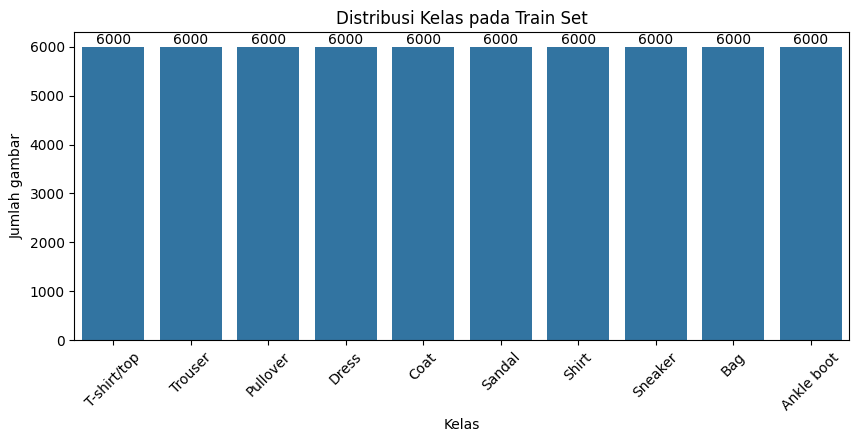

In [3]:
# Buat list atau dictionary yang memetakan label angka (0-9) ke nama kelas.
# Tampilkan distribusi kelas pada train set dalam bentuk bar plot.

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

jumlah_per_kelas = df_train['label'].value_counts().sort_index()

plt.figure(figsize=(10, 4))
ax = sns.barplot(x=class_names, y=jumlah_per_kelas.values)
ax.bar_label(ax.containers[0])
plt.title('Distribusi Kelas pada Train Set')
plt.xlabel('Kelas')
plt.ylabel('Jumlah gambar')
plt.xticks(rotation=45)
plt.show()

Datasetnya seimbang, tiap kelas punya tepat 6.000 gambar di train set. Jadi accuracy sudah cukup adil untuk menilai model, dan tidak perlu penanganan imbalanced.

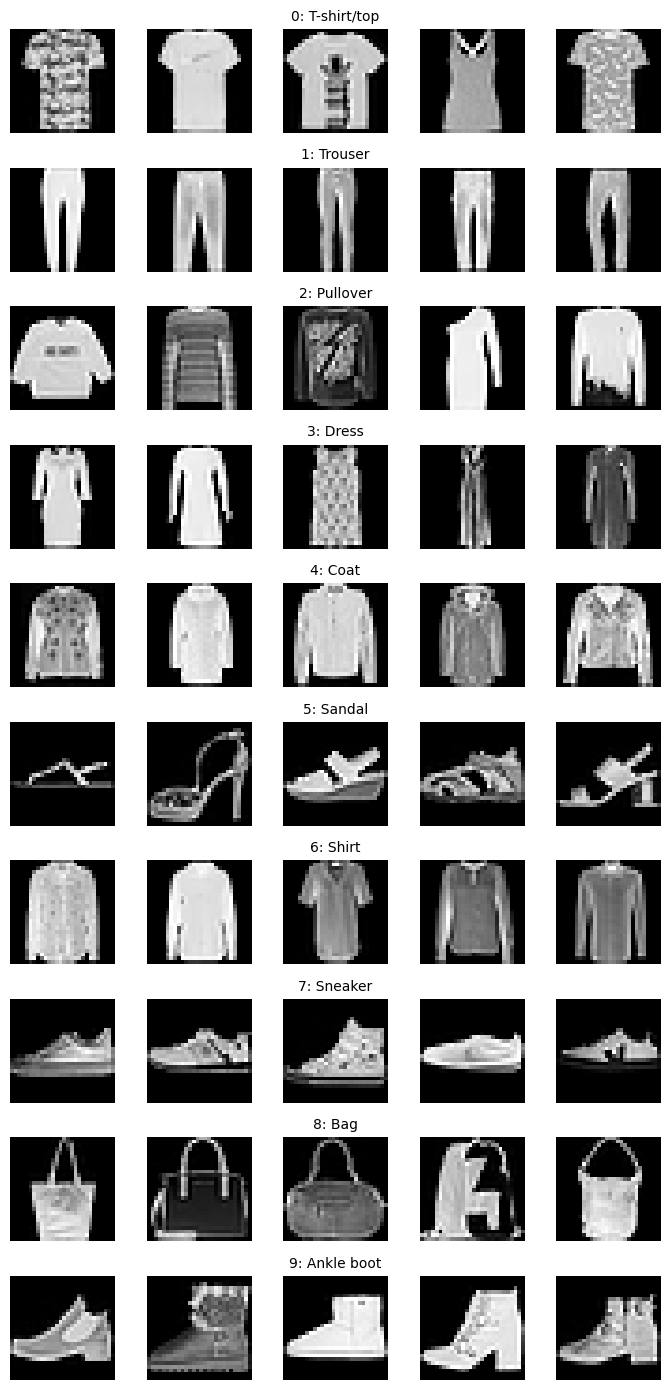

In [4]:
# Tampilkan contoh gambar dari setiap kelas (misalnya grid 10 kelas × 5 gambar) beserta nama kelasnya.
# Kelas mana saja yang secara visual terlihat mirip?

fig, axes = plt.subplots(10, 5, figsize=(7, 14))
for kelas in range(10):
    # ambil 5 gambar pertama dari tiap kelas
    contoh = df_train[df_train['label'] == kelas].drop(columns='label').values[:5]
    for j in range(5):
        axes[kelas, j].imshow(contoh[j].reshape(28, 28), cmap='gray')
        axes[kelas, j].axis('off')
    axes[kelas, 2].set_title(f'{kelas}: {class_names[kelas]}', fontsize=10)
plt.tight_layout()
plt.show()

Kelas yang terlihat mirip:
1. T-shirt/top, Pullover, Coat, dan Shirt. Semuanya atasan dengan bentuk badan dan lengan yang hampir sama, bedanya cuma di detail kecil seperti panjang lengan, kerah, dan kancing.
2. Sneaker dan Ankle boot, sama-sama sepatu yang menghadap ke kiri, bedanya cuma di tinggi bagian atasnya.

Yang paling beda sendiri: Trouser, Bag, dan Sandal.

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

In [5]:
# Cek missing value dan rentang nilai piksel
print('Missing value train:', df_train.isnull().sum().sum())
print('Missing value test :', df_test.isnull().sum().sum())

piksel_train = df_train.drop(columns='label').values
print('Nilai piksel minimum:', piksel_train.min())
print('Nilai piksel maksimum:', piksel_train.max())
print('Persentase piksel yang nilainya 0 (latar hitam):', round((piksel_train == 0).mean() * 100, 1), '%')

print('\nDistribusi kelas pada test set:')
print(df_test['label'].value_counts().sort_index().values)

Missing value train: 0
Missing value test : 0
Nilai piksel minimum: 0
Nilai piksel maksimum: 255
Persentase piksel yang nilainya 0 (latar hitam): 50.2 %

Distribusi kelas pada test set:
[1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


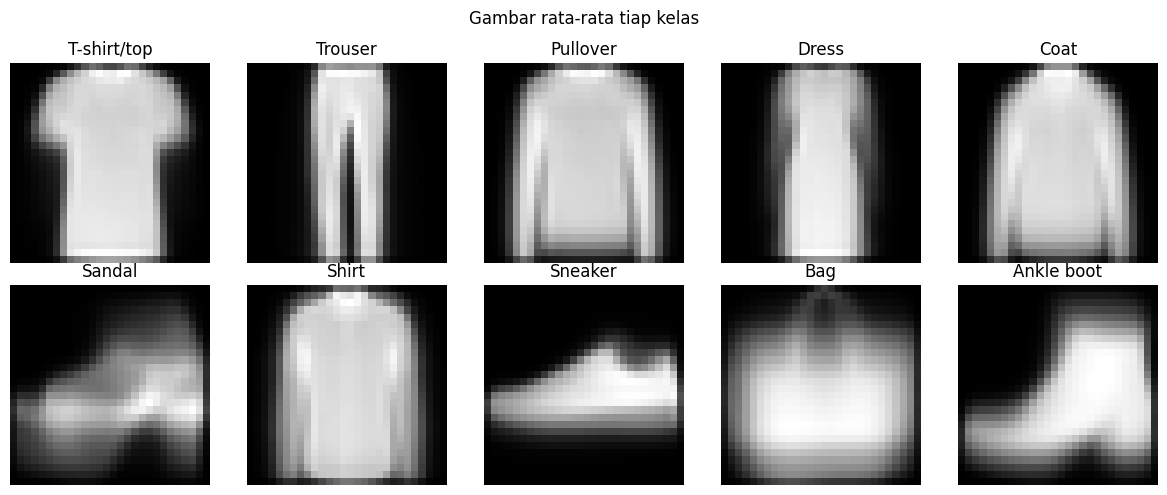

In [6]:
# Gambar rata-rata tiap kelas, untuk melihat bentuk umum setiap jenis pakaian
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for kelas, ax in enumerate(axes.ravel()):
    rata_rata = piksel_train[df_train['label'] == kelas].mean(axis=0)
    ax.imshow(rata_rata.reshape(28, 28), cmap='gray')
    ax.set_title(class_names[kelas])
    ax.axis('off')
plt.suptitle('Gambar rata-rata tiap kelas')
plt.tight_layout()
plt.show()

1. Tidak ada missing value di data train maupun test.
2. Nilai piksel di rentang 0–255, dan sekitar 50.2% piksel nilainya 0 (latar hitam).
3. Test set juga seimbang, tiap kelas 1.000 gambar.
4. Dari gambar rata-rata, Pullover, Coat, dan Shirt bentuknya hampir sama persis (atasan lengan panjang), jadi kemungkinan ini kelas yang paling susah dibedakan. Trouser, Sandal, Sneaker, Bag, dan Ankle boot bentuknya jelas beda.

# 2. Preprocessing

Model yang berbeda membutuhkan bentuk input yang berbeda. Di TensorFlow/Keras, urutan dimensi gambar adalah **(batch, tinggi, lebar, channel)**:

| Model | Bentuk input |
|---|---|
| ANN | `(N, 784)` |
| CNN | `(N, 28, 28, 1)` |

In [7]:
# Pisahkan label (y) dan piksel (X) untuk data train dan test.

y_train_full = df_train['label'].values
X_train_full = df_train.drop(columns='label').values

y_test = df_test['label'].values
X_test = df_test.drop(columns='label').values

print('X_train_full:', X_train_full.shape, '| y_train_full:', y_train_full.shape)
print('X_test      :', X_test.shape, '| y_test      :', y_test.shape)

X_train_full: (60000, 784) | y_train_full: (60000,)
X_test      : (10000, 784) | y_test      : (10000,)


In [8]:
# Normalisasi nilai piksel ke rentang 0-1 (bagi dengan 255).

X_train_full = X_train_full / 255.0
X_test = X_test / 255.0

print('Rentang piksel setelah normalisasi:', X_train_full.min(), '-', X_train_full.max())

Rentang piksel setelah normalisasi: 0.0 - 1.0


In [9]:
# Bagi data train menjadi train set dan validation set (misalnya 90:10) dengan stratify=y.
# Test set dari file fashion-mnist_test.csv hanya digunakan untuk evaluasi akhir.

X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.1,
                                                  stratify=y_train_full, random_state=42)

print('Train     :', X_train.shape, '| jumlah per kelas:', np.bincount(y_train))
print('Validation:', X_val.shape, '| jumlah per kelas:', np.bincount(y_val))
print('Test      :', X_test.shape, '| jumlah per kelas:', np.bincount(y_test))

Train     : (54000, 784) | jumlah per kelas: [5400 5400 5400 5400 5400 5400 5400 5400 5400 5400]
Validation: (6000, 784) | jumlah per kelas: [600 600 600 600 600 600 600 600 600 600]
Test      : (10000, 784) | jumlah per kelas: [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


In [10]:
# Ubah bentuk data sesuai kebutuhan model (lihat tabel di atas), pastikan bertipe float32.
# Contoh untuk CNN: X_train_cnn = X_train.reshape(-1, 28, 28, 1).astype("float32")

# Untuk ANN: (N, 784)
X_train_ann = X_train.astype('float32')
X_val_ann = X_val.astype('float32')
X_test_ann = X_test.astype('float32')

# Untuk CNN: (N, 28, 28, 1)
X_train_cnn = X_train.reshape(-1, 28, 28, 1).astype('float32')
X_val_cnn = X_val.reshape(-1, 28, 28, 1).astype('float32')
X_test_cnn = X_test.reshape(-1, 28, 28, 1).astype('float32')

print('Input ANN:', X_train_ann.shape, X_train_ann.dtype)
print('Input CNN:', X_train_cnn.shape, X_train_cnn.dtype)

Input ANN: (54000, 784) float32
Input CNN: (54000, 28, 28, 1) float32


# 3. Eksperimen Model

## 3.1 ANN (Baseline)

Gambar di-flatten menjadi vektor 784 nilai, lalu diproses oleh ANN biasa. Karena ini klasifikasi multikelas, gunakan **10 neuron output dengan aktivasi Softmax** dan **`sparse_categorical_crossentropy`** sebagai loss function (label berupa angka 0-9).

Contoh arsitektur: `Input(784) → Dense(256, ReLU) → Dense(128, ReLU) → Dense(10, Softmax)`

In [11]:
# Definisikan arsitektur ANN menggunakan keras.Sequential.
# Tampilkan ringkasan model beserta jumlah parameternya dengan model.summary().

model_ann = keras.Sequential([
    keras.Input(shape=(784,)),
    layers.Dense(256, activation='relu'),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax'),
])
model_ann.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# Compile model dengan optimizer, loss="sparse_categorical_crossentropy", dan metrics=["accuracy"].
# Latih model dengan model.fit() menggunakan validation_data, simpan hasilnya ke variabel history.

EPOCHS = 15
BATCH_SIZE = 64

model_ann.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])

history_ann = model_ann.fit(X_train_ann, y_train, validation_data=(X_val_ann, y_val),
                            epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=2)

Epoch 1/15
844/844 - 2s - 2ms/step - accuracy: 0.8216 - loss: 0.5003 - val_accuracy: 0.8477 - val_loss: 0.4108
Epoch 2/15
844/844 - 1s - 2ms/step - accuracy: 0.8664 - loss: 0.3698 - val_accuracy: 0.8603 - val_loss: 0.3761
Epoch 3/15
844/844 - 1s - 1ms/step - accuracy: 0.8790 - loss: 0.3317 - val_accuracy: 0.8692 - val_loss: 0.3584
Epoch 4/15
844/844 - 1s - 2ms/step - accuracy: 0.8869 - loss: 0.3063 - val_accuracy: 0.8767 - val_loss: 0.3304
Epoch 5/15
844/844 - 1s - 2ms/step - accuracy: 0.8929 - loss: 0.2867 - val_accuracy: 0.8750 - val_loss: 0.3335
Epoch 6/15
844/844 - 1s - 2ms/step - accuracy: 0.8994 - loss: 0.2701 - val_accuracy: 0.8763 - val_loss: 0.3358
Epoch 7/15
844/844 - 1s - 2ms/step - accuracy: 0.9052 - loss: 0.2554 - val_accuracy: 0.8755 - val_loss: 0.3375
Epoch 8/15
844/844 - 1s - 1ms/step - accuracy: 0.9087 - loss: 0.2444 - val_accuracy: 0.8757 - val_loss: 0.3481
Epoch 9/15
844/844 - 1s - 1ms/step - accuracy: 0.9138 - loss: 0.2303 - val_accuracy: 0.8818 - val_loss: 0.3382
E

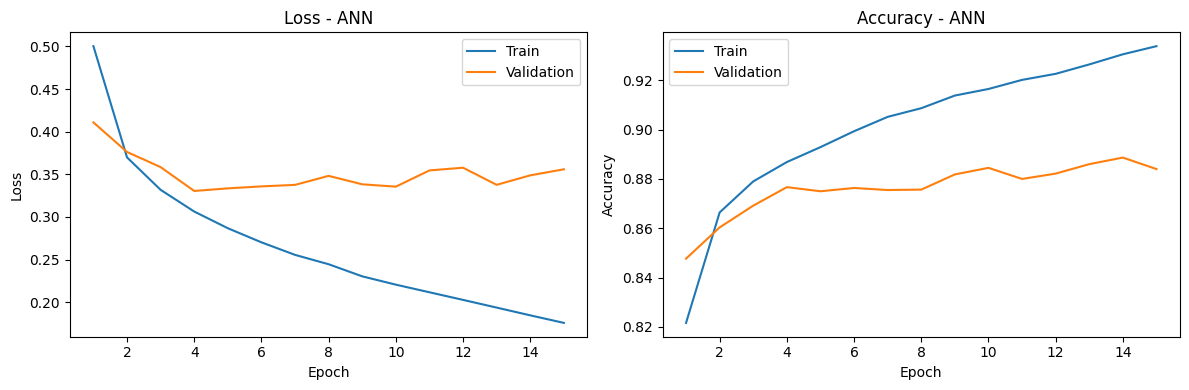

Epoch terakhir -> train acc: 0.9339, val acc: 0.8840, selisih: 0.0499
val_loss paling rendah: 0.3304 (epoch 4), val_loss epoch terakhir: 0.3558


In [13]:
# Tampilkan learning curve (loss dan accuracy) train vs validation.

def plot_learning_curve(history, judul):
    h = history.history
    epoch = range(1, len(h['loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epoch, h['loss'], label='Train')
    axes[0].plot(epoch, h['val_loss'], label='Validation')
    axes[0].set_title(f'Loss - {judul}')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    axes[1].plot(epoch, h['accuracy'], label='Train')
    axes[1].plot(epoch, h['val_accuracy'], label='Validation')
    axes[1].set_title(f'Accuracy - {judul}')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy')
    axes[1].legend()
    plt.tight_layout()
    plt.show()

    # selisih train dan validation di epoch terakhir, untuk melihat overfitting
    print(f"Epoch terakhir -> train acc: {h['accuracy'][-1]:.4f}, val acc: {h['val_accuracy'][-1]:.4f}, "
          f"selisih: {h['accuracy'][-1] - h['val_accuracy'][-1]:.4f}")
    print(f"val_loss paling rendah: {min(h['val_loss']):.4f} (epoch {np.argmin(h['val_loss']) + 1}), "
          f"val_loss epoch terakhir: {h['val_loss'][-1]:.4f}")

plot_learning_curve(history_ann, 'ANN')

Train loss terus turun sampai 0.176, tapi val loss berhenti turun di epoch 4 (0.330) lalu naik pelan-pelan jadi 0.356. Train accuracy 0.934 sedangkan val accuracy mentok di sekitar 0.88. Jadi ANN mulai overfitting setelah epoch 4.

In [14]:
# Lakukan prediksi pada test set. model.predict() menghasilkan probabilitas 10 kelas,
# ambil kelas dengan probabilitas terbesar menggunakan argmax(axis=1). Simpan hasil prediksi label.

proba_ann = model_ann.predict(X_test_ann, verbose=0)
pred_ann = proba_ann.argmax(axis=1)

print('Bentuk output predict:', proba_ann.shape)
print('Contoh prediksi:', pred_ann[:10])
print('Label asli     :', y_test[:10])

Bentuk output predict: (10000, 10)
Contoh prediksi: [0 1 2 2 3 6 8 3 5 0]
Label asli     : [0 1 2 2 3 2 8 6 5 0]


## 3.2 CNN Sederhana

Bangun CNN dengan **2 blok konvolusi**, masing-masing terdiri dari Conv2D (ReLU) → MaxPooling, lalu dilanjutkan Flatten dan Dense.

Contoh arsitektur: `[Conv2D(32, 3×3, ReLU) → MaxPooling2D(2×2)] → [Conv2D(64, 3×3, ReLU) → MaxPooling2D(2×2)] → Flatten → Dense(128, ReLU) → Dense(10, Softmax)`

In [15]:
# Definisikan arsitektur CNN sederhana menggunakan layers.Conv2D, layers.MaxPooling2D, layers.Flatten, dan layers.Dense.
# Gunakan keras.Input(shape=(28, 28, 1)) sebagai layer pertama.
# Tampilkan ringkasan model beserta jumlah parameternya.
# Hitung secara manual ukuran output setiap layer konvolusi dan pooling menggunakan rumus (W - K + 2P) / S + 1,
# lalu cocokkan dengan kolom "Output Shape" pada model.summary(). (padding="valid" berarti P = 0, padding="same" menjaga ukuran tetap)

model_cnn1 = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax'),
])
model_cnn1.summary()

# Hitung manual ukuran output: (W - K + 2P) / S + 1
# Conv2D pakai padding="valid" (P = 0) dan stride 1, MaxPooling 2x2 pakai stride 2.
def ukuran_output(W, K, P, S):
    return (W - K + 2 * P) // S + 1

w1 = ukuran_output(28, 3, 0, 1)   # Conv2D 1   : (28 - 3 + 0) / 1 + 1 = 26
w2 = ukuran_output(w1, 2, 0, 2)   # MaxPooling 1: (26 - 2 + 0) / 2 + 1 = 13
w3 = ukuran_output(w2, 3, 0, 1)   # Conv2D 2   : (13 - 3 + 0) / 1 + 1 = 11
w4 = ukuran_output(w3, 2, 0, 2)   # MaxPooling 2: (11 - 2 + 0) / 2 + 1 = 5 (dibulatkan ke bawah)

print('Hitung manual:')
print(f'Conv2D 1     -> {w1}x{w1}x32')
print(f'MaxPooling 1 -> {w2}x{w2}x32')
print(f'Conv2D 2     -> {w3}x{w3}x64')
print(f'MaxPooling 2 -> {w4}x{w4}x64')
print(f'Flatten      -> {w4 * w4 * 64}')

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Hitung manual:
Conv2D 1     -> 26x26x32
MaxPooling 1 -> 13x13x32
Conv2D 2     -> 11x11x64
MaxPooling 2 -> 5x5x64
Flatten      -> 1600


Hasil hitung manual sama dengan kolom Output Shape di `model.summary()`: 26×26 → 13×13 → 11×11 → 5×5, lalu Flatten jadi 5 × 5 × 64 = 1600.

Di MaxPooling kedua hasilnya (11 − 2) / 2 + 1 = 5.5, dibulatkan ke bawah jadi 5 (baris dan kolom terakhir tidak ikut).

Epoch 1/15
844/844 - 6s - 7ms/step - accuracy: 0.8188 - loss: 0.4991 - val_accuracy: 0.8632 - val_loss: 0.3775
Epoch 2/15
844/844 - 5s - 6ms/step - accuracy: 0.8780 - loss: 0.3317 - val_accuracy: 0.8863 - val_loss: 0.3160
Epoch 3/15
844/844 - 5s - 6ms/step - accuracy: 0.8956 - loss: 0.2839 - val_accuracy: 0.8930 - val_loss: 0.2866
Epoch 4/15
844/844 - 5s - 6ms/step - accuracy: 0.9085 - loss: 0.2493 - val_accuracy: 0.9000 - val_loss: 0.2681
Epoch 5/15
844/844 - 5s - 6ms/step - accuracy: 0.9191 - loss: 0.2215 - val_accuracy: 0.9020 - val_loss: 0.2633
Epoch 6/15
844/844 - 5s - 6ms/step - accuracy: 0.9282 - loss: 0.1976 - val_accuracy: 0.9030 - val_loss: 0.2642
Epoch 7/15
844/844 - 5s - 6ms/step - accuracy: 0.9353 - loss: 0.1754 - val_accuracy: 0.9063 - val_loss: 0.2656
Epoch 8/15
844/844 - 5s - 6ms/step - accuracy: 0.9433 - loss: 0.1558 - val_accuracy: 0.9048 - val_loss: 0.2738
Epoch 9/15
844/844 - 5s - 6ms/step - accuracy: 0.9501 - loss: 0.1383 - val_accuracy: 0.9002 - val_loss: 0.2908
E

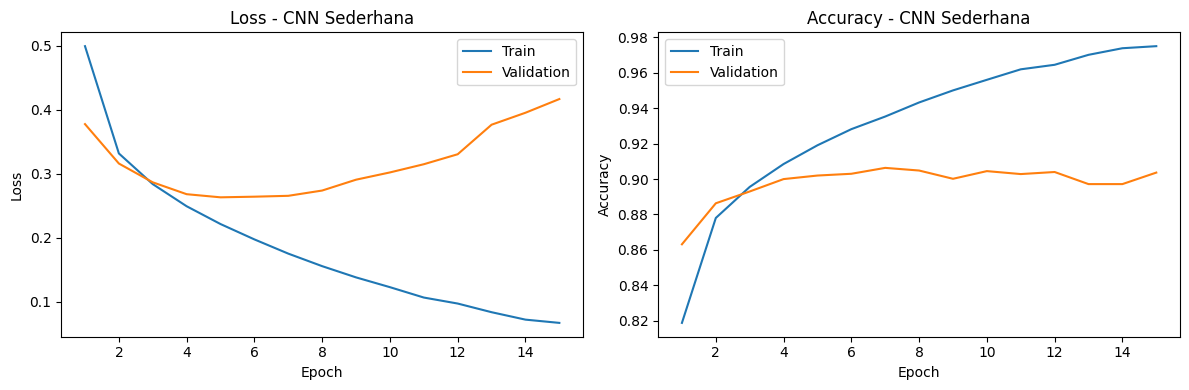

Epoch terakhir -> train acc: 0.9751, val acc: 0.9037, selisih: 0.0714
val_loss paling rendah: 0.2633 (epoch 5), val_loss epoch terakhir: 0.4166


In [16]:
# Latih model dengan pengaturan yang sama seperti 3.1 agar perbandingan adil.
# Tampilkan learning curve train vs validation.

model_cnn1.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                   loss='sparse_categorical_crossentropy', metrics=['accuracy'])

history_cnn1 = model_cnn1.fit(X_train_cnn, y_train, validation_data=(X_val_cnn, y_val),
                              epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=2)

plot_learning_curve(history_cnn1, 'CNN Sederhana')

CNN sederhana overfitting-nya lebih jelas dari ANN. Val loss paling rendah di epoch 5 (0.263), setelah itu naik terus sampai 0.417, padahal train loss turun sampai 0.067. Train accuracy 0.975 tapi val accuracy tetap di sekitar 0.90 (selisih 0.071).

In [17]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.

proba_cnn1 = model_cnn1.predict(X_test_cnn, verbose=0)
pred_cnn1 = proba_cnn1.argmax(axis=1)

## 3.3 CNN dengan Batch Normalization dan Dropout

Gunakan arsitektur CNN pada 3.2, lalu tambahkan **Batch Normalization** setelah setiap layer konvolusi dan **Dropout** sebelum layer output.

In [18]:
# Definisikan arsitektur CNN dengan Batch Normalization dan Dropout.
# Urutan yang umum: Conv2D (tanpa activation) -> layers.BatchNormalization() -> layers.Activation("relu") -> MaxPooling2D.
# Tambahkan layers.Dropout(rate) sebelum layer output.
# Tampilkan ringkasan model beserta jumlah parameternya.

model_cnn2 = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3)),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3)),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax'),
])
model_cnn2.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 26, 26, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 26, 26, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 11, 11, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 11, 11, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,418 (880.54 KB)

 Trainable params: 225,226 (879.79 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/15
844/844 - 11s - 12ms/step - accuracy: 0.7860 - loss: 0.5969 - val_accuracy: 0.8492 - val_loss: 0.4126
Epoch 2/15
844/844 - 9s - 11ms/step - accuracy: 0.8503 - loss: 0.4205 - val_accuracy: 0.8805 - val_loss: 0.3256
Epoch 3/15
844/844 - 9s - 11ms/step - accuracy: 0.8674 - loss: 0.3734 - val_accuracy: 0.8882 - val_loss: 0.3055
Epoch 4/15
844/844 - 9s - 11ms/step - accuracy: 0.8772 - loss: 0.3413 - val_accuracy: 0.8842 - val_loss: 0.3048
Epoch 5/15
844/844 - 9s - 11ms/step - accuracy: 0.8869 - loss: 0.3161 - val_accuracy: 0.8978 - val_loss: 0.2839
Epoch 6/15
844/844 - 10s - 12ms/step - accuracy: 0.8907 - loss: 0.3000 - val_accuracy: 0.8943 - val_loss: 0.2956
Epoch 7/15
844/844 - 10s - 11ms/step - accuracy: 0.8973 - loss: 0.2828 - val_accuracy: 0.9020 - val_loss: 0.2749
Epoch 8/15
844/844 - 9s - 11ms/step - accuracy: 0.9036 - loss: 0.2664 - val_accuracy: 0.9048 - val_loss: 0.2691
Epoch 9/15
844/844 - 10s - 11ms/step - accuracy: 0.9065 - loss: 0.2534 - val_accuracy: 0.9035 - val_l

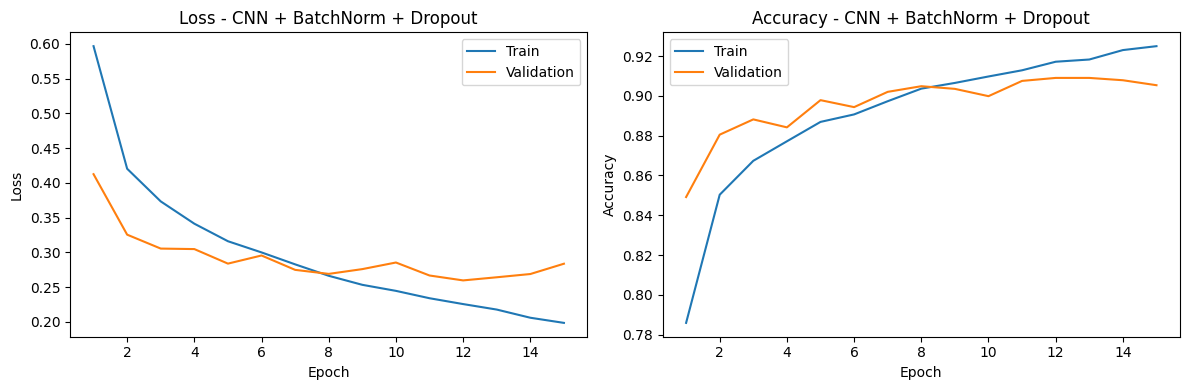

Epoch terakhir -> train acc: 0.9249, val acc: 0.9053, selisih: 0.0196
val_loss paling rendah: 0.2597 (epoch 12), val_loss epoch terakhir: 0.2837


In [19]:
# Latih model dengan pengaturan yang sama seperti 3.2.
# Tampilkan learning curve train vs validation.
# Perhatikan selisih antara train dan validation dibandingkan dengan model 3.2.

model_cnn2.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                   loss='sparse_categorical_crossentropy', metrics=['accuracy'])

history_cnn2 = model_cnn2.fit(X_train_cnn, y_train, validation_data=(X_val_cnn, y_val),
                              epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=2)

plot_learning_curve(history_cnn2, 'CNN + BatchNorm + Dropout')

1. Selisih train dan validation accuracy jauh lebih kecil: 0.020 (model 3.2: 0.071).
2. Val loss tidak naik tajam seperti model 3.2. Paling rendah di epoch 12 (0.260) dan di epoch terakhir masih 0.284 (model 3.2: 0.417).
3. Train accuracy lebih rendah (0.925 vs 0.975) karena Dropout mematikan setengah neuron waktu training. Di awal training val accuracy malah lebih tinggi dari train accuracy karena alasan yang sama.

In [20]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.

proba_cnn2 = model_cnn2.predict(X_test_cnn, verbose=0)
pred_cnn2 = proba_cnn2.argmax(axis=1)

# 4. Evaluasi Model

In [21]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score (macro average),
# beserta jumlah parameter setiap model. Sajikan dalam satu tabel perbandingan.

hasil_model = {
    'ANN': (model_ann, pred_ann),
    'CNN Sederhana': (model_cnn1, pred_cnn1),
    'CNN + BatchNorm + Dropout': (model_cnn2, pred_cnn2),
}

rows = []
for nama, (model, pred) in hasil_model.items():
    rows.append({
        'model': nama,
        'accuracy': accuracy_score(y_test, pred),
        'precision': precision_score(y_test, pred, average='macro'),
        'recall': recall_score(y_test, pred, average='macro'),
        'f1_score': f1_score(y_test, pred, average='macro'),
        'jumlah_parameter': model.count_params(),
    })

tabel_evaluasi = pd.DataFrame(rows).set_index('model').round(4)
tabel_evaluasi

,accuracy,precision,recall,f1_score,jumlah_parameter
model,,,,,
ANN,0.8860,0.8901,0.8860,0.8873,235146
CNN Sederhana,0.9072,0.9081,0.9072,0.9072,225034
CNN + BatchNorm + Dropout,0.9102,0.9119,0.9102,0.9081,225418


Kedua CNN lebih bagus dari ANN, padahal jumlah parameternya sedikit lebih sedikit (±225 ribu vs ±235 ribu). CNN + BatchNorm + Dropout paling tinggi, tapi selisihnya dengan CNN sederhana kecil (0.9102 vs 0.9072).

In [22]:
# Tampilkan classification report (metrik per kelas) untuk model terbaik.

# Model terbaik dipilih dari tabel di atas: CNN + BatchNorm + Dropout,
# karena accuracy (0.9102) dan F1-score (0.9081) di test set paling tinggi.
nama_terbaik = 'CNN + BatchNorm + Dropout'
model_terbaik, pred_terbaik = hasil_model[nama_terbaik]

print('Model terbaik:', nama_terbaik)
print(classification_report(y_test, pred_terbaik, target_names=class_names, digits=4))

Model terbaik: CNN + BatchNorm + Dropout
              precision    recall  f1-score   support

 T-shirt/top     0.7699    0.9300    0.8424      1000
     Trouser     0.9870    0.9870    0.9870      1000
    Pullover     0.8430    0.8970    0.8692      1000
       Dress     0.9159    0.9260    0.9209      1000
        Coat     0.8721    0.8730    0.8726      1000
      Sandal     0.9867    0.9680    0.9773      1000
       Shirt     0.8487    0.6060    0.7071      1000
     Sneaker     0.9597    0.9520    0.9558      1000
         Bag     0.9879    0.9800    0.9839      1000
  Ankle boot     0.9479    0.9830    0.9651      1000

    accuracy                         0.9102     10000
   macro avg     0.9119    0.9102    0.9081     10000
weighted avg     0.9119    0.9102    0.9081     10000



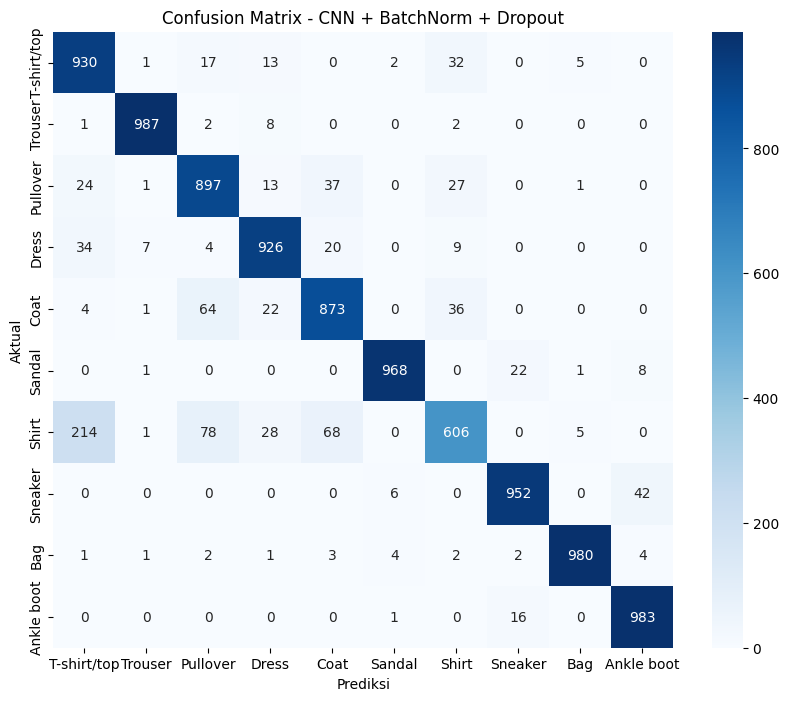

5 kesalahan paling sering:
Shirt diprediksi sebagai T-shirt/top: 214 gambar
Shirt diprediksi sebagai Pullover: 78 gambar
Shirt diprediksi sebagai Coat: 68 gambar
Coat diprediksi sebagai Pullover: 64 gambar
Sneaker diprediksi sebagai Ankle boot: 42 gambar


In [23]:
# Tampilkan Confusion Matrix 10×10 model terbaik dalam bentuk heatmap, gunakan nama kelas sebagai label sumbu.
# Pasangan kelas mana yang paling sering tertukar?

cm = confusion_matrix(y_test, pred_terbaik)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title(f'Confusion Matrix - {nama_terbaik}')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

# Cari pasangan kelas yang paling sering tertukar (di luar diagonal)
salah = []
for i in range(10):
    for j in range(10):
        if i != j:
            salah.append((cm[i, j], class_names[i], class_names[j]))
salah.sort(reverse=True)

print('5 kesalahan paling sering:')
for jumlah, asli, prediksi in salah[:5]:
    print(f'{asli} diprediksi sebagai {prediksi}: {jumlah} gambar')

Pasangan yang paling sering tertukar:
1. **Shirt → T-shirt/top**: 214 gambar. Ini yang paling banyak. Sebaliknya (T-shirt/top → Shirt) cuma 32.
2. **Shirt → Pullover** (78) dan **Shirt → Coat** (68).
3. **Coat ↔ Pullover**: 64 dan 37.
4. **Sneaker → Ankle boot**: 42.

Jadi Shirt adalah kelas yang paling susah (recall cuma 0.606), sesuai dengan dugaan waktu EDA kalau kelas atasan saling mirip.

Jumlah gambar yang salah diklasifikasikan: 898 dari 10000


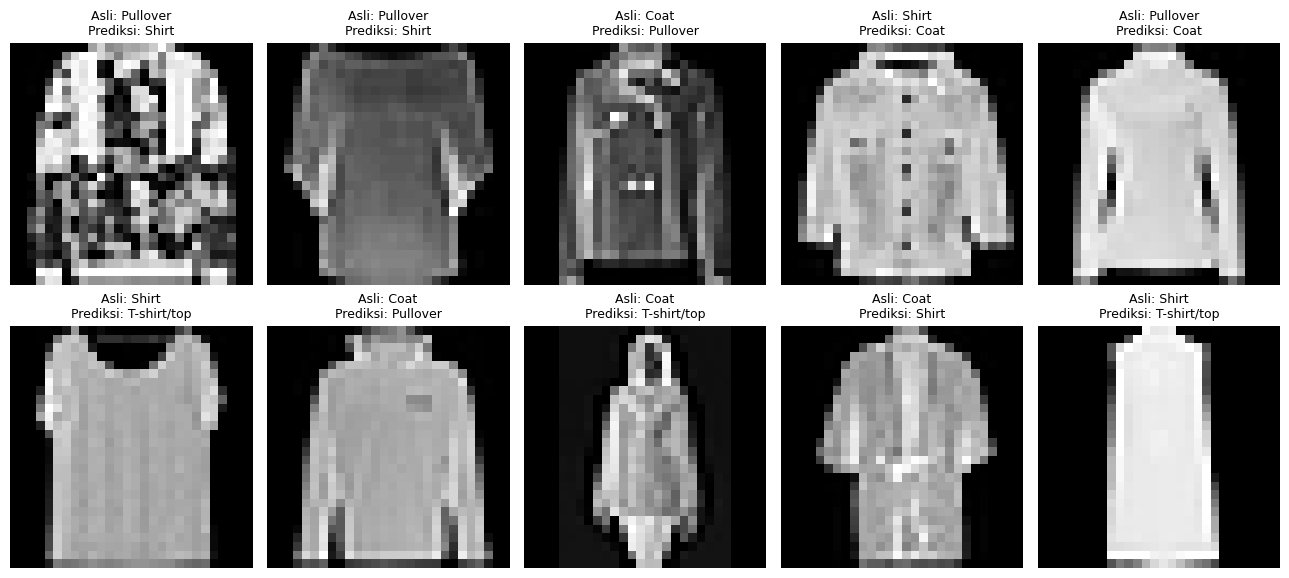

In [24]:
# Tampilkan beberapa contoh gambar yang salah diklasifikasikan oleh model terbaik,
# beserta label asli dan label prediksinya.

idx_salah = np.where(pred_terbaik != y_test)[0]
print('Jumlah gambar yang salah diklasifikasikan:', len(idx_salah), 'dari', len(y_test))

fig, axes = plt.subplots(2, 5, figsize=(13, 6))
for ax, idx in zip(axes.ravel(), idx_salah[:10]):
    ax.imshow(X_test[idx].reshape(28, 28), cmap='gray')
    ax.set_title(f'Asli: {class_names[y_test[idx]]}\nPrediksi: {class_names[pred_terbaik[idx]]}', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

Dari 10 contoh di atas, semua kesalahan terjadi antar kelas atasan (Shirt, Pullover, Coat, T-shirt/top). Beberapa gambarnya memang susah dibedakan walaupun dilihat pakai mata sendiri.

Layer pertama: conv2d_2
Bentuk feature map: (1, 26, 26, 32)


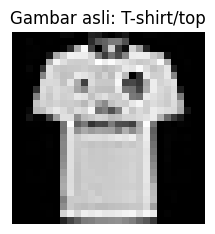

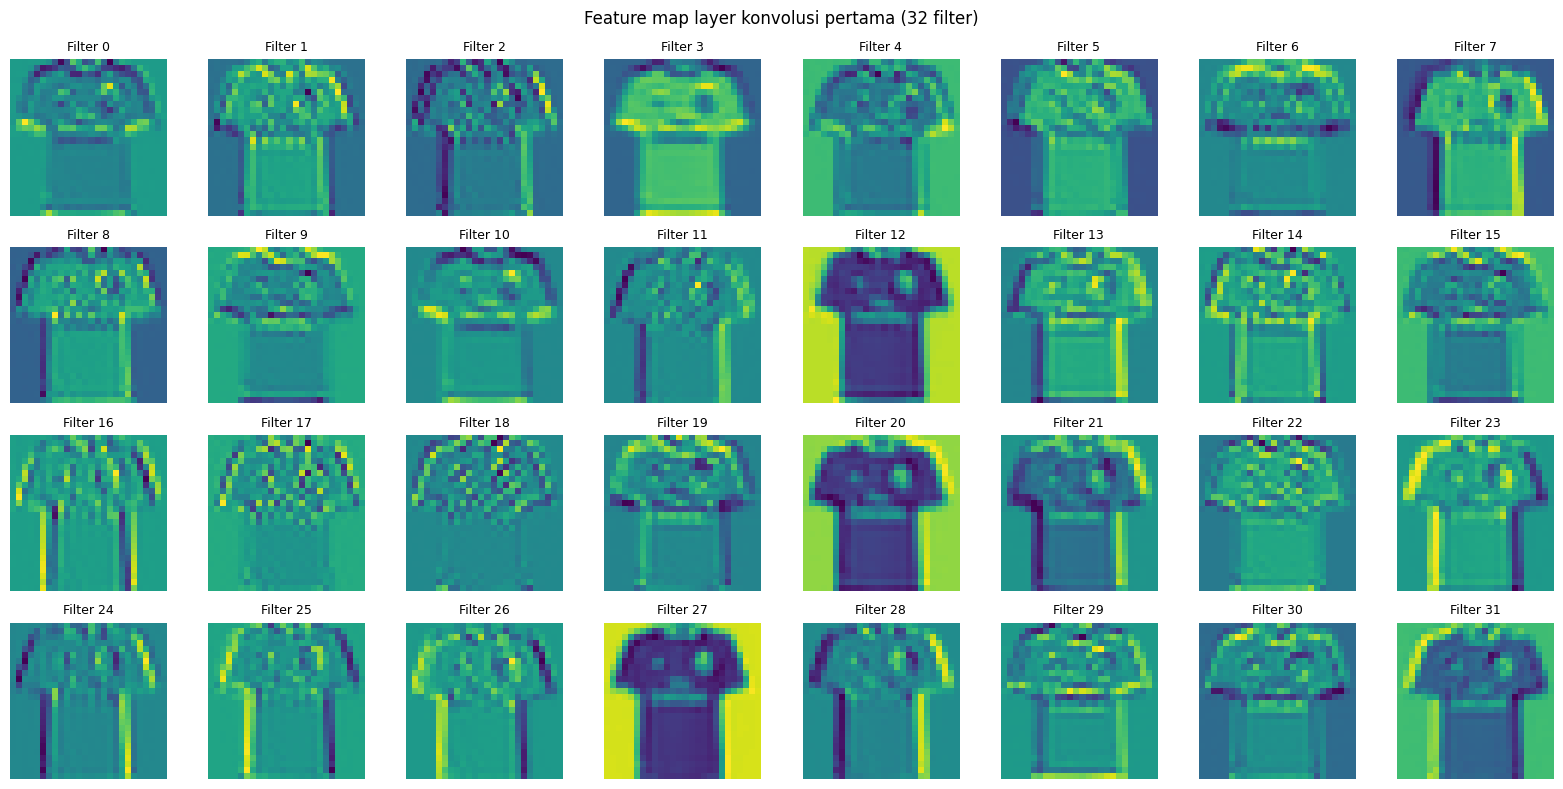

In [25]:
# Visualisasikan feature map dari layer konvolusi pertama model terbaik untuk satu gambar contoh.
# Buat model baru yang output-nya adalah output layer konvolusi pertama:
#   feature_model = keras.Model(inputs=model.inputs, outputs=model.layers[0].output)
# lalu tampilkan setiap channel hasil feature_model.predict() sebagai gambar.
# Apa saja pola yang ditangkap oleh masing-masing filter?

# layers[0] adalah layer Conv2D pertama (keras.Input tidak dihitung sebagai layer)
print('Layer pertama:', model_terbaik.layers[0].name)
feature_model = keras.Model(inputs=model_terbaik.inputs, outputs=model_terbaik.layers[0].output)

idx_contoh = 0
gambar = X_test_cnn[idx_contoh:idx_contoh + 1]
feature_map = feature_model.predict(gambar, verbose=0)
print('Bentuk feature map:', feature_map.shape)

plt.figure(figsize=(2.5, 2.5))
plt.imshow(gambar[0, :, :, 0], cmap='gray')
plt.title(f'Gambar asli: {class_names[y_test[idx_contoh]]}')
plt.axis('off')
plt.show()

fig, axes = plt.subplots(4, 8, figsize=(16, 8))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(feature_map[0, :, :, i], cmap='viridis')
    ax.set_title(f'Filter {i}', fontsize=9)
    ax.axis('off')
plt.suptitle('Feature map layer konvolusi pertama (32 filter)')
plt.tight_layout()
plt.show()

Layer konvolusi pertama menghasilkan 32 feature map berukuran 26×26. Pola yang ditangkap:
1. **Tepi vertikal**: filter 7, 16, 23, 24, 25 menyala di sisi kiri/kanan badan dan lengan baju.
2. **Tepi horizontal**: filter 6, 9, 10, 29 menyala di bagian bahu, ujung lengan, dan bawah baju.
3. **Latar belakang**: filter 12, 20, 27 menyala di area hitam di luar baju, jadi seperti memisahkan bentuk baju dari latar.
4. **Bagian dalam baju**: filter 3 menyala di seluruh area baju yang terang.
5. **Detail/tekstur**: filter 17, 18, 22 menyala di gambar sablon di bagian dada.

Jadi layer pertama baru menangkap fitur sederhana seperti tepi dan terang-gelap, belum bentuk pakaian secara utuh.

In [26]:
# Simpan model terbaik dengan model.save("model.keras").
# Model ini akan digunakan kembali pada tugas Deployment.

model_terbaik.save('model.keras')

# Cek: muat ulang model lalu pastikan accuracy-nya sama
model_cek = keras.models.load_model('model.keras')
loss_cek, acc_cek = model_cek.evaluate(X_test_cnn, y_test, verbose=0)
print('Model tersimpan sebagai model.keras')
print('Accuracy test setelah dimuat ulang:', round(acc_cek, 4))

Model tersimpan sebagai model.keras
Accuracy test setelah dimuat ulang: 0.9102


# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan. Bandingkan performa ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout berdasarkan hasil evaluasi. Kaitkan perbedaan performa dengan jumlah parameter dan cara masing-masing model memproses gambar. Bahas pula pengaruh Batch Normalization dan Dropout terhadap learning curve, serta kelas-kelas yang sulit dibedakan oleh model. Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan.

1. **Perbandingan performa.** CNN + BatchNorm + Dropout paling bagus (accuracy 0.9102, F1 0.9081), lalu CNN sederhana (0.9072), dan terakhir ANN (0.8860). Jadi CNN lebih tinggi sekitar 2–2.4% dari ANN.
2. **Jumlah parameter dan cara memproses gambar.** Parameter ANN (235.146) malah sedikit lebih banyak dari CNN (225.034 dan 225.418), tapi hasilnya lebih rendah. Jadi yang membuat CNN lebih bagus bukan jumlah parameternya, tapi cara memproses gambarnya. ANN meratakan gambar jadi 784 angka sehingga posisi piksel yang bertetangga hilang. CNN memakai kernel 3×3 yang digeser ke seluruh gambar, jadi bisa menangkap pola lokal seperti tepi dan tekstur di posisi mana pun. Layer Conv2D-nya sendiri cuma 320 + 18.496 parameter, sisanya ada di Dense.
3. **Overfitting.** ANN dan CNN sederhana sama-sama overfitting. Val loss ANN berhenti turun di epoch 4, val loss CNN sederhana paling rendah di epoch 5 (0.263) lalu naik sampai 0.417 walaupun train accuracy-nya 0.975.
4. **Pengaruh Batch Normalization dan Dropout.** Selisih train dan validation accuracy turun dari 0.071 jadi 0.020, dan val loss di epoch terakhir jauh lebih rendah (0.284 vs 0.417). Train accuracy-nya lebih rendah (0.925) karena Dropout membuat training lebih susah, tapi hasil di test set malah sedikit lebih bagus. Tambahan parameternya juga sangat sedikit (cuma 384 dari BatchNorm). Val loss-nya masih agak naik-turun dan mulai naik sedikit setelah epoch 12, jadi overfitting-nya berkurang tapi belum hilang total.
5. **Kelas yang sulit dibedakan.** Shirt paling susah: recall cuma 0.606 dan F1 0.707, karena 214 gambar Shirt ditebak sebagai T-shirt/top, 78 sebagai Pullover, dan 68 sebagai Coat. Coat dan Pullover juga sering tertukar (64 dan 37). Ini masuk akal karena di gambar 28×28 detail seperti kancing dan kerah hampir tidak kelihatan. Sebaliknya Trouser, Bag, dan Sandal hampir selalu benar (F1 0.98–0.99) karena bentuknya beda sendiri.
6. **Feature map.** Filter di layer konvolusi pertama menangkap tepi vertikal, tepi horizontal, latar belakang, dan tekstur. Ini fitur yang tidak bisa dipelajari ANN secara langsung.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan. Saran dapat berupa rekomendasi untuk eksperimen selanjutnya, perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

**Kesimpulan**
1. CNN lebih cocok untuk data gambar daripada ANN: accuracy test 0.907–0.910 vs 0.886, padahal jumlah parameternya hampir sama (±225 ribu vs ±235 ribu).
2. Model terbaik adalah CNN + Batch Normalization + Dropout dengan accuracy 0.9102 dan F1-score 0.9081. 
3. Batch Normalization dan Dropout paling terasa pengaruhnya di overfitting (selisih train-validation turun dari 0.071 jadi 0.020), sedangkan kenaikan accuracy test-nya kecil (0.9072 → 0.9102).
4. Kelas yang paling susah adalah Shirt (recall 0.606) karena mirip dengan T-shirt/top, Pullover, dan Coat. Kelas yang paling mudah adalah Trouser, Bag, dan Sandal.

**Saran**
1. Pakai EarlyStopping, karena val loss terbaik sudah tercapai sebelum epoch 15 (epoch 5 untuk CNN sederhana, epoch 12 untuk CNN + BatchNorm + Dropout).
2. Coba data augmentation (misalnya geser atau flip horizontal) supaya model lebih bisa membedakan kelas atasan.
3. Coba tambah blok konvolusi atau pakai padding="same" supaya ukuran feature map tidak cepat mengecil.
4. Coba dropout rate dan learning rate yang lain, atau tambah Dropout setelah blok konvolusi.
5. Jalankan di GPU (Colab/Kaggle) supaya training lebih cepat. Di sini training masih pakai CPU karena GPU tidak terdeteksi.